# NN_L7_confusion

**Lecture 7 of Neural Networks and Deep Learning (NN), attention and transformers. Confusion matrices of FinBERT on the test tweets, zero-shot and after fine-tuning (seed 1).**

Neural Networks and Deep Learning (NN), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L7/NN_L7_confusion/NN_L7_confusion.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Rows = observed class, columns = predicted class; 0 bearish, 1 bullish, 2 neutral.

bearish found, zero-shot = 264   [cm_zs.bear_ok]
bearish found, fine-tuned = 288   [cm.bear_ok]
bearish read as neutral, fine-tuned = 47   [cm.bear_as_neutral]


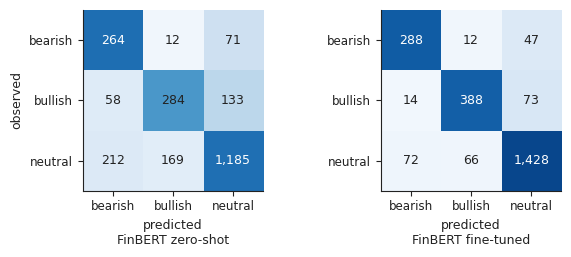

In [3]:
p = pd.read_csv(REPO + 'lectures/L7/results/' + 'test_predictions.csv')
from sklearn.metrics import confusion_matrix
cz, cf = confusion_matrix(p.y, p.finbert_zs, labels=[0, 1, 2]), confusion_matrix(p.y, p.finbert_ft, labels=[0, 1, 2])
show('cm_zs.bear_ok', 'bearish found, zero-shot', int(cz[0, 0]))
show('cm.bear_ok', 'bearish found, fine-tuned', int(cf[0, 0]))
show('cm.bear_as_neutral', 'bearish read as neutral, fine-tuned', int(cf[0, 2]))
cn = ['bearish', 'bullish', 'neutral']
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.7))
for ax, M, ttl in [(axs[0], cz, 'FinBERT zero-shot'), (axs[1], cf, 'FinBERT fine-tuned')]:
    Mn = M / M.sum(1, keepdims=True); ax.imshow(Mn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{M[i, j]:,}', ha='center', va='center', color='white' if Mn[i, j] > 0.6 else '#222222', fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(cn, fontsize=8.5); ax.set_yticks(range(3)); ax.set_yticklabels(cn, fontsize=8.5); ax.set_xlabel('predicted\n' + ttl, fontsize=9)
axs[0].set_ylabel('observed', fontsize=9)
fig.tight_layout()
fig.savefig('confusion.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()